### Банковский маркетинг, набор UCI 222. Нужно предсказать, оформит ли клиент депозит.

In [2]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path("..").resolve()))
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from src.common import load_dataset, split_data, build_preprocessor, get_feature_names

df = load_dataset()
print("Размер таблицы:", df.shape)
print("Дубликаты:", df.duplicated().sum())
display(df.head())

Размер таблицы: (45211, 17)
Дубликаты: 0


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [3]:
nulls = df.isnull().sum()
null_df = pd.DataFrame({
    "Число пропусков": nulls[nulls > 0],
    "Доля, %": (nulls[nulls > 0] / len(df) * 100).round(2),
})
print("Пропуски:")
display(null_df)
vc = df["y"].value_counts()
ratio = vc["no"] / vc["yes"]
print(f"Классы: отказ={vc['no']} ({vc['no']/len(df)*100:.2f}%), депозит={vc['yes']} ({vc['yes']/len(df)*100:.2f}%)")
print(f"Дисбаланс: {vc['yes']/vc['no']:.4f}, или 1 к {ratio:.2f}")

Пропуски:


,Число пропусков,"Доля, %"
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


Классы: отказ=39922 (88.30%), депозит=5289 (11.70%)
Дисбаланс: 0.1325, или 1 к 7.55


### Смотрим баланс классов, длительность звонка, возраст и результат прошлых звонков.

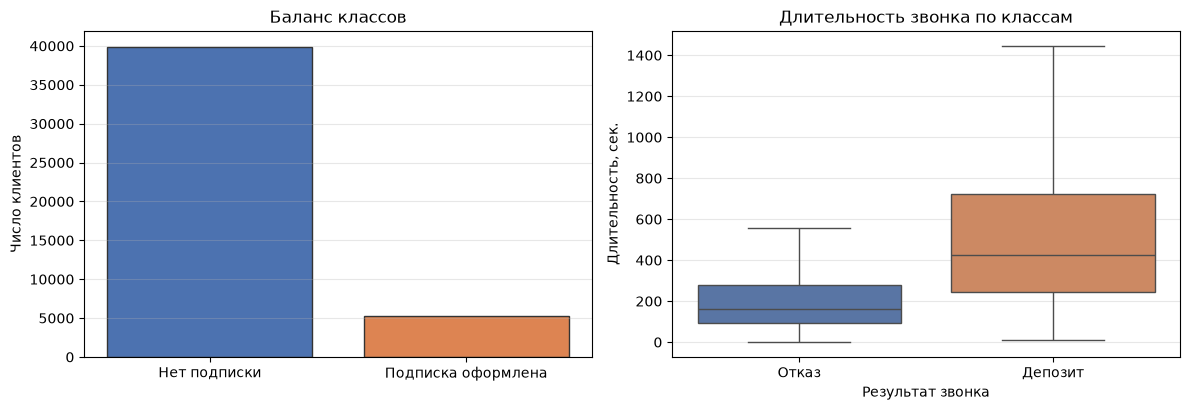

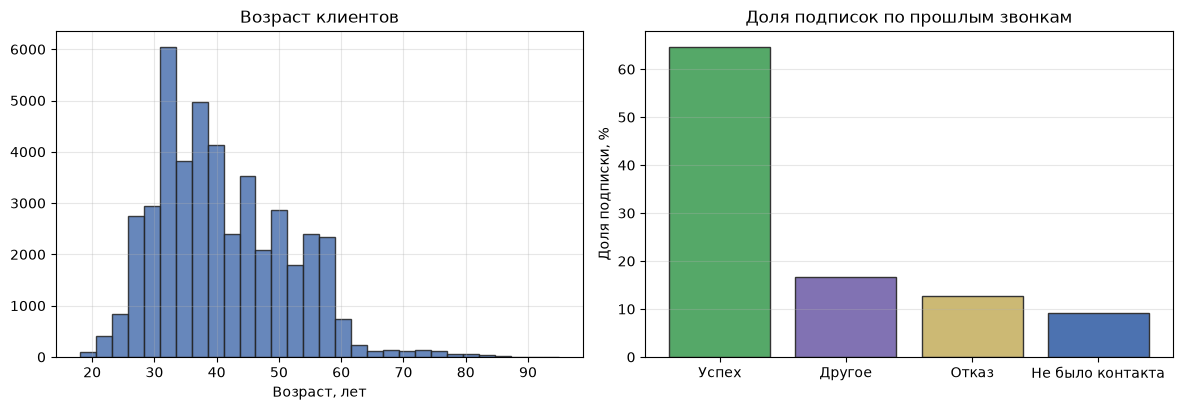

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(["Нет подписки", "Подписка оформлена"], [vc["no"], vc["yes"]], color=["#4C72B0", "#DD8452"], edgecolor="#333")
axes[0].set_title("Баланс классов")
axes[0].set_ylabel("Число клиентов")
axes[0].grid(True, axis="y", alpha=0.3)

df_box = df.assign(класс=df["y"].map({"no": "Отказ", "yes": "Депозит"}))
sns.boxplot(data=df_box, x="класс", y="duration", showfliers=False, palette={"Отказ": "#4C72B0", "Депозит": "#DD8452"}, ax=axes[1])
axes[1].set_title("Длительность звонка по классам")
axes[1].set_xlabel("Результат звонка")
axes[1].set_ylabel("Длительность, сек.")
axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

df_po = df.assign(poutcome_clean=df["poutcome"].fillna("unknown"))
po_map = {"success": "Успех", "other": "Другое", "failure": "Отказ", "unknown": "Не было контакта"}
po_rate = (df_po.groupby("poutcome_clean")["y"].apply(lambda s: (s == "yes").mean() * 100)
           .reindex(["success", "other", "failure", "unknown"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(df["age"], bins=30, color="#4C72B0", edgecolor="#222", alpha=0.85)
axes[0].set_title("Возраст клиентов")
axes[0].set_xlabel("Возраст, лет")
axes[0].grid(True, alpha=0.3)

axes[1].bar([po_map[k] for k in po_rate.index], po_rate.values, color=["#55A868", "#8172B3", "#CCB974", "#4C72B0"], edgecolor="#333")
axes[1].set_title("Доля подписок по прошлым звонкам")
axes[1].set_ylabel("Доля подписки, %")
axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Разбиение и подготовка признаков

In [4]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)
pre = build_preprocessor(scale_numeric=False)
X_train_proc = pre.fit_transform(X_train)
X_test_proc = pre.transform(X_test)
feat_names = get_feature_names(pre)

print(f"Обучение: {X_train.shape}, тест: {X_test.shape}")
print(f"Признаков после кодирования: {len(feat_names)}")
print("Пропусков осталось (обучение/тест):", int(pd.isna(X_train_proc).sum()), int(pd.isna(X_test_proc).sum()))

Обучение: (36168, 16), тест: (9043, 16)
Признаков после кодирования: 51
Пропусков осталось (обучение/тест): 0 0
